# 1. FASE: Planificación Estratégica

## 1.1 Planteamiento y Delimitación del Problema
La deserción laboral voluntaria suele abordarse desde discursos condescendientes o reactivos de gestión del clima, pasando por alto sus costos estructurales y sus detonantes profundos. Lejos de ser un evento aislado, la salida intempestiva de personal evidencia problemas en el diseño de los perfiles profesionales, sobrecarga de funciones y posibles incumplimientos de contratos laborales.

El propósito de este proyecto no es romantizar la retención, es simular un escenario donde se necesite modelar de forma predictiva los patrones de fuga voluntaria a partir de datos organizacionales para fundamentar decisiones objetivas en talento humano hacia el futuro.



## 1.2 Enfoque Interdisciplinario:
Los resultados cuantitativos de este notebook, se contrastarán bajo dos marcos analíticos complementarios:

* **Perspectiva Psicológica:**
  * Evaluación del desgaste laboral y la percepción de inequidad.
  * Análisis del quiebre del contrato psicológico derivado del estancamiento en promociones, desbalances en compensación y falta de autonomía o reconocimiento.
  * El impacto psicosocial y la sobrecarga que asumen los colaboradores que permanecen en la estructura.

* **Perspectiva JurídicoLaboral y el Riesgo:**
  * Detección de factores de exposición legal vinculados a jornadas extenuantes, incumplimientos contractuales.
  * Monitoreo de riesgos psicosociales conforme a los estándares de seguridad y salud en el trabajo.
  * Prevención de contingencias económicas asociadas a liquidaciones repetitivas, rotación por acoso laboral pasivo o configuraciones de despido indirecto por desmejora en las condiciones operativas.



## 1.3 Alcance Técnico y Criterios de Éxito
* **Naturaleza del problema:** Clasificación binaria sobre datos desbalanceados de casos positivos de renuncia.
* **Métrica importante:** **Recall** en la clase de renuncia. En la gestión del riesgo laboral y humano, el no anticipar una renuncia inminente en un área crítica situación conocido técnicamente como **falso Negativo** lo que implica pérdida de conocimiento clave, sobrecostos inmediatos y riesgo legal. Mientras que un **Falso Positivo** demanda una revisión preventiva de condiciones o una conversación de seguimiento, centrarnos en ellos podría generar un desgaste de los recursos de la institución.
* **Métrica de soporte:** **ROC-AUC** para verificar la capacidad del sistema de diferenciar perfiles estables de perfiles en vulnerabilidad de salida sin sesgarse por el desbalance, y pudiendo reconocer su riesgo.

# 2. FASE:  Analizar

## 2.1 Auditoría
Estudiar el dataset para asegurarnos que cuente con la información necesaria, antes de realizar cualquier modelaje, para evitar errores futuros o incluso llegar a conclusiones que no sean utiles
1. **Estandarización:** Traducción y normalización de variables técnicas y la traducción de idioma (p. ej. *Stock Options*, horas extras, nivel de puesto).
2. **integridad:** Confirmación de ausencia de registros duplicados y valores nulos (`NaN`).
3. **Revisión de varianza:**
   * Detección y eliminación de variables constantes (varianza cero: sin poder discriminante, es decir solamente tienen un valor).
   * Identificación del identificador secuencial (`ID_Empleado`), el cual generaría sobreajuste  al memorizar registros en lugar de aprender patrones.

**1.Estandarización**

In [14]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np


ruta = '/content/drive/MyDrive/Colab Notebooks/datasets/ibm_art.csv'
df = pd.read_csv(ruta)

print(f"Total filas: {df.shape[0]} | Total columnas: {df.shape[1]}")
df.head(5)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total filas: 1470 | Total columnas: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2




> Es un gusto personal de traer a mi idioma nativo lo que estoy aprendiendo, pues siento que es una necesidad que evolucionemos en este campo




In [15]:

columnas_espanol = {
    'Age': 'Edad',
    'Gender': 'Genero',
    'MaritalStatus': 'Estado_Civil',
    'Education': 'Nivel_Educativo',
    'EducationField': 'Area',
    'DistanceFromHome': 'Distancia_casa',
    'Attrition': 'Rotacion',
    'Department': 'Departamento',
    'JobRole': 'Cargo',
    'JobLevel': 'Nivel_Puesto',
    'BusinessTravel': 'Viajes_por_trabajo',
    'OverTime': 'Horas_Extras',
    'MonthlyIncome': 'Salario_Mensual',
    'DailyRate': 'Salario_día_laboral',
    'HourlyRate': 'Salario_hora_labor',
    'MonthlyRate': 'Tarifa_Mensual',
    'PercentSalaryHike': 'Porcentaje_Aumento_Salario',
    'StockOptionLevel': 'Oportunidad_ser_Accionista',
    'EnvironmentSatisfaction': 'Satisfaccion_Empresa',
    'JobInvolvement': 'Compromiso',
    'JobSatisfaction': 'Satisfaccion_cargo',
    'RelationshipSatisfaction': 'Satisfaccion_compañeros',
    'WorkLifeBalance': 'Balance_Sociolaboral',
    'PerformanceRating': 'Desempeño',
    'TotalWorkingYears': 'Años_Experiencia_Laboral',
    'YearsAtCompany': 'Antiguedad_Empresa',
    'YearsInCurrentRole': 'Años_cargo',
    'YearsSinceLastPromotion': 'Años_Ascenso',
    'YearsWithCurrManager': 'Años_mismo_Gerente',
    'NumCompaniesWorked': 'Numero_Empresas',
    'TrainingTimesLastYear': 'Capacitaciones_ultimo_año',
    'EmployeeNumber': 'ID_Empleado',
    'EmployeeCount': 'Conteo_Empleado',
    'StandardHours': 'Horas_Estandar',
    'Over18': 'Mayor_Edad'
}
df = df.rename(columns=columnas_espanol)
df.columns.tolist()

['Edad',
 'Rotacion',
 'Viajes_por_trabajo',
 'Salario_día_laboral',
 'Departamento',
 'Distancia_casa',
 'Nivel_Educativo',
 'Area',
 'Conteo_Empleado',
 'ID_Empleado',
 'Satisfaccion_Empresa',
 'Genero',
 'Salario_hora_labor',
 'Compromiso',
 'Nivel_Puesto',
 'Cargo',
 'Satisfaccion_cargo',
 'Estado_Civil',
 'Salario_Mensual',
 'Tarifa_Mensual',
 'Numero_Empresas',
 'Mayor_Edad',
 'Horas_Extras',
 'Porcentaje_Aumento_Salario',
 'Desempeño',
 'Satisfaccion_compañeros',
 'Horas_Estandar',
 'Oportunidad_ser_Accionista',
 'Años_Experiencia_Laboral',
 'Capacitaciones_ultimo_año',
 'Balance_Sociolaboral',
 'Antiguedad_Empresa',
 'Años_cargo',
 'Años_Ascenso',
 'Años_mismo_Gerente']

In [16]:

df['Horas_Extras'] = df['Horas_Extras'].replace({
    'Yes': 'Si',
    'No': 'No'
})
df['Viajes_por_trabajo'] = df['Viajes_por_trabajo'].replace({
    'Non-Travel': 'Sin_Viajes',
    'Travel_Rarely': 'Viaja_Raras_Veces',
    'Travel_Frequently': 'Viaja_Frecuentemente'
})
df['Cargo'] = df['Cargo'].replace({
    'Sales Executive': 'Ejecutivo_Ventas',
    'Research Scientist': 'Cientifico_Investigacion',
    'Laboratory Technician': 'Tecnico_Laboratorio',
    'Manufacturing Director': 'Director_Manufactura',
    'Healthcare Representative': 'Representante_Salud',
    'Manager': 'Gerente',
    'Sales Representative': 'Representante_Ventas',
    'Research Director': 'Director_Investigacion',
    'Human Resources': 'Recursos_Humanos'
})
if 'Area' in df.columns:
    df['Area'] = df['Area'].replace({
        'Life Sciences': 'Ciencias_Naturales',
        'Medical': 'Medicina',
        'Marketing': 'Mercadeo',
        'Technical Degree': 'Carrera_Tecnica',
        'Other': 'Otro',
        'Human Resources': 'Recursos_Humanos'
    })
if 'Departamento' in df.columns:
    df['Departamento'] = df['Departamento'].replace({
        'Sales': 'Ventas',
        'Research & Development': 'Investigacion_Desarrollo',
        'Human Resources': 'Recursos_Humanos'
    })
if 'Estado_Civil' in df.columns:
    df['Estado_Civil'] = df['Estado_Civil'].replace({
        'Single': 'Soltero',
        'Married': 'Casado',
        'Divorced': 'Divorciado'
    })

**2. Integridad**
Revición de duplicados, nulos o inconstencias.

In [17]:
# Duplicados
duplicados = df.duplicated().sum()
# Nulos
nulos = df.isna().sum().sum()
# Resumen
print(f"Filas duplicadas : {duplicados}")
print(f"Valores nulos  totales  : {nulos}")

if duplicados == 0 and nulos == 0:
    print(" Base sin nulos o duplicados.")
else:
    print("Necesidad de limpiar.")

Filas duplicadas : 0
Valores nulos  totales  : 0
 Base sin nulos o duplicados.


**3. Revisión de Varianza**

In [18]:
resumen_valores = df.nunique().sort_values()
print("Columnas con menor cantidad de valores únicos")
print(resumen_valores.head(8))
print("\nColumnas con mayor cantidad de valores únicos")
print(resumen_valores.tail(5))

Columnas con menor cantidad de valores únicos
Conteo_Empleado       1
Mayor_Edad            1
Horas_Estandar        1
Rotacion              2
Horas_Extras          2
Desempeño             2
Genero                2
Viajes_por_trabajo    3
dtype: int64

Columnas con mayor cantidad de valores únicos
Salario_hora_labor       71
Salario_día_laboral     886
Salario_Mensual        1349
Tarifa_Mensual         1427
ID_Empleado            1470
dtype: int64


In [19]:
columnas_descartables = ['Conteo_Empleado', 'Horas_Estandar', 'Mayor_Edad', 'ID_Empleado']
df = df.drop(columns=columnas_descartables)

df.columns.tolist()

['Edad',
 'Rotacion',
 'Viajes_por_trabajo',
 'Salario_día_laboral',
 'Departamento',
 'Distancia_casa',
 'Nivel_Educativo',
 'Area',
 'Satisfaccion_Empresa',
 'Genero',
 'Salario_hora_labor',
 'Compromiso',
 'Nivel_Puesto',
 'Cargo',
 'Satisfaccion_cargo',
 'Estado_Civil',
 'Salario_Mensual',
 'Tarifa_Mensual',
 'Numero_Empresas',
 'Horas_Extras',
 'Porcentaje_Aumento_Salario',
 'Desempeño',
 'Satisfaccion_compañeros',
 'Oportunidad_ser_Accionista',
 'Años_Experiencia_Laboral',
 'Capacitaciones_ultimo_año',
 'Balance_Sociolaboral',
 'Antiguedad_Empresa',
 'Años_cargo',
 'Años_Ascenso',
 'Años_mismo_Gerente']

# 3. FASE: Construir

## 3.1 Preparación de Datos
* **Binarización:** Codificación directa de `Rotacion` (1 = Renuncia, 0 = Permanece).
* **Conversión:** Conversión de variables categóricas  con `drop_first=True, dtype=int` para evitar redundancia.
* **Partición:** División 80/20 con `stratify=y` para asegurar que la proporción real de renuncias se mantenga idéntica tanto al entrenar como al evaluar.
* **Estandarización:** Aplicación de `StandardScaler` ajustado exclusivamente en el conjunto de entrenamiento para evitar perdida de información

## 3.2 Modelos Predictivos

### Modelo 1: Regresión Logística
* **Enfoque técnico:** Modelo lineal probabilístico con ajuste de pesos (`class_weight='balanced'`) para establecer una línea base  rápida y medir el efecto directo de cada variable.
* **Valor:** Identificar con claridad matemática qué factores aumentan o disminuyen el riesgo de salida de forma individual.

### Modelo 2: Árbol de Decisión Podado
* **Enfoque técnico:** Algoritmo no lineal basado en particiones sucesivas con restricción de profundidad y muestras mínimas para prevenir sobreajuste.
* **Valor para el negocio:** Generar un mapa visual de reglas claras que permita a gestión humana ver combinaciones críticas específicas (presuntamente. ej., "si viaja frecuentemente Y tiene bajo nivel de puesto -> alerta de renuncia").

### Modelo 3: Random Forest
* **Enfoque técnico:** Ensamble de cientos de árboles de decisión mediante muestreo aleatorio, lo que reduce el margen de error y la varianza de un solo árbol.
* **Valor para el negocio:** Estimar una probabilidad individual de rotación para priorizar posibles intervenciones para dimensionar cuántos y qué colaboradores específicos están en riesgo crítico, permitiendo priorizar planes de retención y cuantificar el impacto general en la plantilla.


## 3.3 Protocolo de Evaluación
* **Métrica de Cobertura - Recall:** Minimizar falsos negativos; intentar identificar oportunamente a la mayor cantidad posible de colaboradores en riesgo de renuncia.
* **Métrica de Eficiencia - Precision & F1-Score:** Fundamental para no saturar al área de Talento Humano con falsas alarmas, buscando un equilibrio operativo donde las alertas rojas sean confiables.
* **Métrica global - ROC-AUC:** Indicador de referencia para contrastar la capacidad general de discriminación probabilística entre los tres modelos.
* **Matriz de Confusión:** Cuantificación operativa directa en número de personas  para evaluar la viabilidad real de los planes de intervención.

## 3.4 Interpretabilidad y Auditoría Algorítmica (SHAP)
* **Enfoque técnico:** Implementación de `shap.TreeExplainer` basado en la teoría de juegos cooperativos sobre el ensamble seleccionado `Random Forest`.
* **Propósito metodológico:** abrir la "caja negra" del modelo evaluando la contribución, el impacto y las interacciones no lineales de cada variable en las predicciones.
* **Valor para el negocio:** Validar que las alertas se sustenten en causas laborales consistentes y accionables (e.g., sobrecarga horaria o desfase salarial) antes de trasladar las recomendaciones a comités directivos.

**3.1 Preparación de datos**

**Se aclara que la intención del proyecto es simular una empresa real, por esto, se habla de población en riesgo, se deja en claro que es un caso simulado y que por eso se emplean esos conceptos.**

Abordar la variable objetivo de estudio la cual es "Rotación", de forma que podamos utilizarla, modelarla, combinarla, transformarla, compararla, etc




In [20]:
## Binarización
df['Rotacion'] = df['Rotacion'].map({'Yes': 1, 'No': 0})
# Se calcula porcentaje de rotación:
print(f"Tasa base de rotación: {df['Rotacion'].mean() * 100:.2f}%")
#  Matriz X, Vector Y
X = df.drop(columns=['Rotacion'])
y = df['Rotacion']
## Conversión
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)
print(f"Matriz: {X_encoded.shape[0]} registros y {X_encoded.shape[1]}")

Tasa base de rotación: 16.12%
Matriz: 1470 registros y 44


In [21]:
!pip install shap -q
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
## Partición:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
## Estandarización
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**3.2 Modelos predictivos**

**Regresión Logística**

Reporte Clasificación
              precision    recall  f1-score   support

           0       0.91      0.77      0.84       247
           1       0.33      0.60      0.43        47

    accuracy                           0.74       294
   macro avg       0.62      0.68      0.63       294
weighted avg       0.82      0.74      0.77       294

ROC-AUC: 0.7985


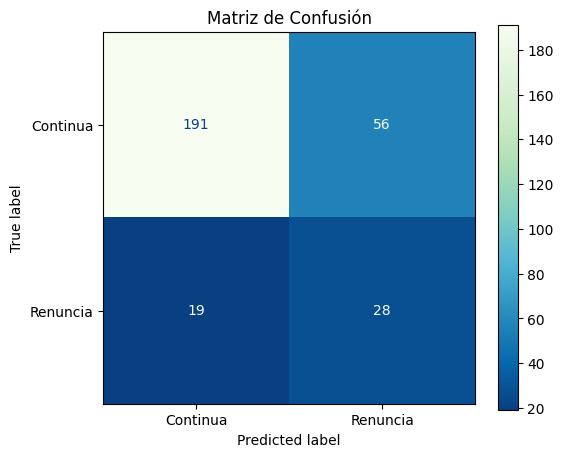

In [22]:
## Entrenamiento Modelo
modelo_lr = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
modelo_lr.fit(X_train_scaled, y_train)
## Predicciones y métricas
y_pred_lr = modelo_lr.predict(X_test_scaled)
y_prob_lr = modelo_lr.predict_proba(X_test_scaled)[:, 1]

print("Reporte Clasificación")
print(classification_report(y_test, y_pred_lr))

print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["Continua", "Renuncia"],
    cmap="GnBu_r",
    ax=ax
)
plt.title("Matriz de Confusión")
plt.grid(False)
plt.show()

In [23]:
odds_ratios = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente_Beta': modelo_lr.coef_[0],
    'Odds_Ratio': np.exp(modelo_lr.coef_[0])
}).sort_values(by='Odds_Ratio', ascending=False)

print(odds_ratios.head(10))

                                   Variable  Coeficiente_Beta  Odds_Ratio
43                          Horas_Extras_Si          0.773363    2.167042
23  Viajes_por_trabajo_Viaja_Frecuentemente          0.724078    2.062828
7                              Nivel_Puesto          0.673979    1.962028
24     Viajes_por_trabajo_Viaja_Raras_Veces          0.515658    1.674740
40                Cargo_Tecnico_Laboratorio          0.506702    1.659808
21                             Años_Ascenso          0.499002    1.647077
37                   Cargo_Recursos_Humanos          0.481552    1.618585
11                          Numero_Empresas          0.461785    1.586904
39               Cargo_Representante_Ventas          0.372597    1.451499
2                            Distancia_casa          0.325415    1.384605


**Resultados**

In [24]:
df_coef = pd.DataFrame({
    'Variable': X_encoded.columns,
    'Coeficiente': modelo_lr.coef_[0]
}).sort_values(by='Coeficiente', ascending=False)

## Variables asociadas a la deserción
print("Principales variables asociadas con la probabilidad estimada de rotación según el modelo.")
display(df_coef.head(5))

## Variables asociadas a mantener el talento
print("\nPrincipales variables asociadas con la probabilidad estimada de quedarse según el modelo.")
display(df_coef.tail(5))

Principales variables asociadas con la probabilidad estimada de rotación según el modelo.


,Variable,Coeficiente
43,Horas_Extras_Si,0.773363
23,Viajes_por_trabajo_Viaja_Frecuentemente,0.724078
7,Nivel_Puesto,0.673979
24,Viajes_por_trabajo_Viaja_Raras_Veces,0.515658
40,Cargo_Tecnico_Laboratorio,0.506702



Principales variables asociadas con la probabilidad estimada de quedarse según el modelo.


,Variable,Coeficiente
4,Satisfaccion_Empresa,-0.439498
25,Departamento_Recursos_Humanos,-0.456942
22,Años_mismo_Gerente,-0.472300
33,Cargo_Director_Investigacion,-0.567867
16,Años_Experiencia_Laboral,-0.657140


**Evaluación**

In [25]:
df_evaluacion = X_test.copy()
df_evaluacion['Real_Renuncio'] = y_test
df_evaluacion['Probabilidad_Renuncia'] = (y_prob_lr * 100).round(1)

## Niveles de riesgo
def clasificar_riesgo(p):
    if p >= 70:
        return 'Crítico'
    elif p >= 40:
        return 'Medio'
    else:
        return 'Bajo'

df_evaluacion['Nivel_Riesgo'] = df_evaluacion['Probabilidad_Renuncia'].apply(clasificar_riesgo)
print("Distribución por nivel de riesgo:")
print(df_evaluacion['Nivel_Riesgo'].value_counts())

Distribución por nivel de riesgo:
Nivel_Riesgo
Bajo       191
Medio       58
Crítico     45
Name: count, dtype: int64


Los umbrales utilizados son parámetros operativos definidos por medio de los ODDS que nos sugiere el modelo de regresión logística

**Función de los ODDS:**

El Odd compara directamente a los que se van contra los que se quedan:$$\text{Odd} = \frac{P}{1 - P}$$En esa simulación, la rotación de base ronda el 16%.Eso significa que por cada 16 personas que renuncian, 84 se quedan. Su Odd base es:$$\text{Odd base} = \frac{0.16}{0.84} \approx 0.19$$

**Por qué el 70% es el corte de Riesgo Crítico**

según los Odds Cuando el modelo le asigna a un colaborador una probabilidad del 70%, sus posibilidades relativas de salida se transforman por completo:$$\text{Odd} = \frac{0.70}{0.30} \approx 2.33$$

La comparación de un colaborador con esta probabilidad ($2,33$) con la de un empleado promedio ($0.19$), el riesgo relativo está multiplicado por más de 12 veces ($2.33 / 0.19 \approx 12.2$). siendo presuntamente una situación crítica.

**Riesgo Medio o Moderado**

($40\% \le P < 70\%$):   A partir de $P = 40\%$, el momio individual se eleva a:$$\text{Odd} = \frac{0.40}{0.60} \approx 0.67$$Aunque la permanencia aún supera a la salida (0.67 a 1), el riesgo relativo individual representa más de 3.5 veces la tasa habitual de la empresa ($0.67 / 0.19 \approx 3.5$).

 Constituye una zona de alerta temprana para seguimiento preventivo sin saturar la capacidad operativa.

**Riesgo Bajo**

 $$\text{$P < 40\%$}\$$

 Comportamiento estadísticamente cercano a la línea base ordinaria de la organización.

Conocer quienes son:

In [26]:
casos_criticos = df_evaluacion[df_evaluacion['Nivel_Riesgo'] == 'Crítico'].sort_values(
    by='Probabilidad_Renuncia',
    ascending=False
)
columnas_mostrar = ['Probabilidad_Renuncia', 'Real_Renuncio']
## Dar contexto
variables_contexto = [col for col in ['Horas_Extras_Si', 'Nivel_Puesto', 'Satisfaccion_Empresa'] if col in df_evaluacion.columns]

display(casos_criticos[columnas_mostrar + variables_contexto].head(10))

,Probabilidad_Renuncia,Real_Renuncio,Horas_Extras_Si,Nivel_Puesto,Satisfaccion_Empresa
357,99.3,1,1,1,1
911,98.8,1,1,1,3
688,96.8,1,1,1,4
946,96.6,1,1,3,4
1021,96.4,1,0,1,1
762,95.3,1,1,1,1
132,94.1,1,1,2,2
310,93.8,0,0,2,1
514,93.6,1,1,1,1
525,92.0,1,0,2,1


**Riesgo Latente**

In [27]:
## No han renunciado pero hay riesgo.
riesgo_latente = df_evaluacion[
    (df_evaluacion['Real_Renuncio'] == 0) &
    (df_evaluacion['Nivel_Riesgo'].isin(['Crítico', 'Medio']))
].sort_values(by='Probabilidad_Renuncia', ascending=False)

print(f"Riesgo latente detectados: {len(riesgo_latente)}")
print(f" - En riesgo Crítico: {sum(riesgo_latente['Nivel_Riesgo'] == 'Crítico')}")
print(f" - En riesgo Medio: {sum(riesgo_latente['Nivel_Riesgo'] == 'Medio')}")

## Casos con mayor probabilidad de renunciar
columnas_interes = ['Probabilidad_Renuncia', 'Nivel_Riesgo']
display(riesgo_latente[columnas_interes].head(10))

Riesgo latente detectados: 65
 - En riesgo Crítico: 23
 - En riesgo Medio: 42


,Probabilidad_Renuncia,Nivel_Riesgo
310,93.8,Crítico
929,89.1,Crítico
824,89.1,Crítico
496,88.8,Crítico
301,86.7,Crítico
1168,86.5,Crítico
196,86.4,Crítico
347,85.8,Crítico
841,85.8,Crítico
1391,84.7,Crítico


**Árbol de Decisión Podado**

Clasificación
              precision    recall  f1-score   support

           0       0.92      0.74      0.82       247
           1       0.32      0.64      0.43        47

    accuracy                           0.73       294
   macro avg       0.62      0.69      0.62       294
weighted avg       0.82      0.73      0.76       294

ROC-AUC: 0.6990


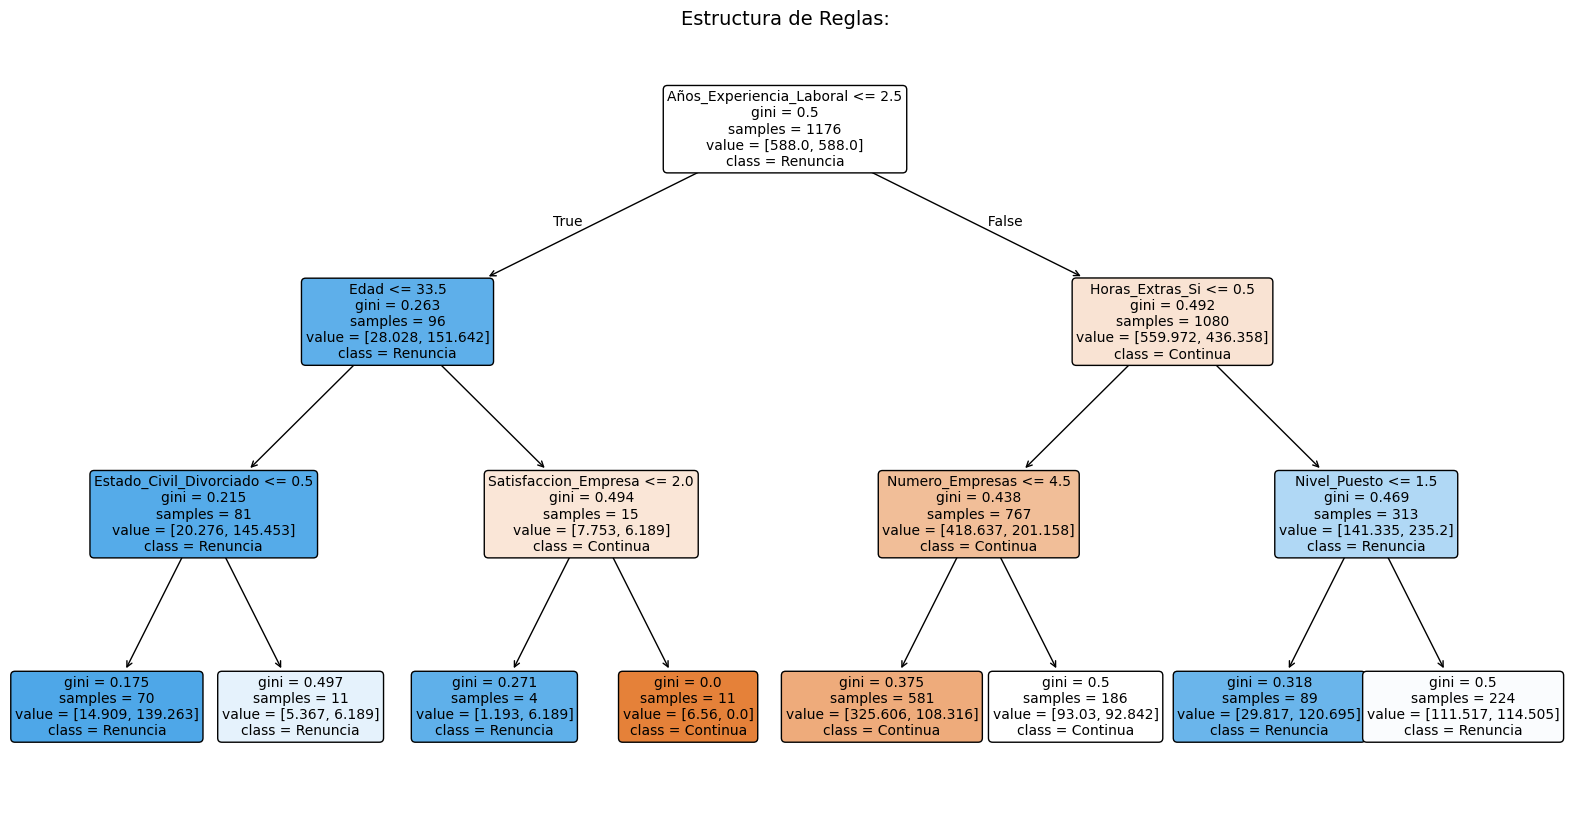

In [28]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

## Definir y entrenar el árbol
modelo_tree = DecisionTreeClassifier(
    max_depth=3,
    class_weight='balanced',
    random_state=42
)
modelo_tree.fit(X_train, y_train)
## Predicciones y métricas
y_pred_tree = modelo_tree.predict(X_test)
y_prob_tree = modelo_tree.predict_proba(X_test)[:, 1]
print("Clasificación")
print(classification_report(y_test, y_pred_tree))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_tree):.4f}")
## Graficar
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_tree,
    feature_names=X_encoded.columns,
    class_names=["Continua", "Renuncia"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura de Reglas:", fontsize=14)
plt.show()

**Resultados**

In [29]:
df_imp_tree = pd.DataFrame({
    'Variable': X_encoded.columns,
    'Importancia_%': (modelo_tree.feature_importances_ * 100).round(2)
}).sort_values(by='Importancia_%', ascending=False)

print("Variables determinantes")
display(df_imp_tree[df_imp_tree['Importancia_%'] > 0])

##Probabilidades
df_eval_tree = X_test.copy()
df_eval_tree['Real_Renuncio'] = y_test
df_eval_tree['Probabilidad_Renuncia_%'] = (y_prob_tree * 100).round(1)

## Niveles de riesgo
def nivel_riesgo_tree(p):
    if p >= 70:
        return 'Crítico'
    elif p >= 40:
        return 'Medio'
    else:
        return 'Bajo'

df_eval_tree['Nivel_Riesgo'] = df_eval_tree['Probabilidad_Renuncia_%'].apply(nivel_riesgo_tree)

Variables determinantes


,Variable,Importancia_%
16,Años_Experiencia_Laboral,36.63
43,Horas_Extras_Si,30.79
11,Numero_Empresas,11.86
7,Nivel_Puesto,11.50
4,Satisfaccion_Empresa,3.56
0,Edad,3.53
41,Estado_Civil_Divorciado,2.12


**Riesgo Latente**

In [30]:
## Riesgos
riesgo_latente_tree = df_eval_tree[
    (df_eval_tree['Real_Renuncio'] == 0) &
    (df_eval_tree['Nivel_Riesgo'].isin(['Crítico', 'Medio']))
].sort_values(by='Probabilidad_Renuncia_%', ascending=False)

print("\nRiesgos segun el modelo de Arbol de decisión podado")
print(df_eval_tree['Nivel_Riesgo'].value_counts())

print(f"\nColaboradores activos en riesgo: {len(riesgo_latente_tree)}")
display(riesgo_latente_tree[['Probabilidad_Renuncia_%', 'Nivel_Riesgo']].head(10))


Riesgos segun el modelo de Arbol de decisión podado
Nivel_Riesgo
Bajo       156
Medio       87
Crítico     51
Name: count, dtype: int64

Colaboradores activos en riesgo: 104


,Probabilidad_Renuncia_%,Nivel_Riesgo
1061,90.3,Crítico
1311,90.3,Crítico
476,90.3,Crítico
1349,90.3,Crítico
160,90.3,Crítico
246,90.3,Crítico
929,90.3,Crítico
670,90.3,Crítico
934,90.3,Crítico
764,90.3,Crítico


**Random Forest**

In [31]:
from sklearn.ensemble import RandomForestClassifier
## Definir y entrenar
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
modelo_rf.fit(X_train, y_train)

# Predicción y  probabilidades
y_pred_rf = modelo_rf.predict(X_test)
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Rendimiento
print("Reporte de clasificación")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

Reporte de clasificación
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       247
           1       0.42      0.49      0.45        47

    accuracy                           0.81       294
   macro avg       0.66      0.68      0.67       294
weighted avg       0.82      0.81      0.82       294

ROC-AUC: 0.7776


/tmp/ipykernel_2578/1470221308.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


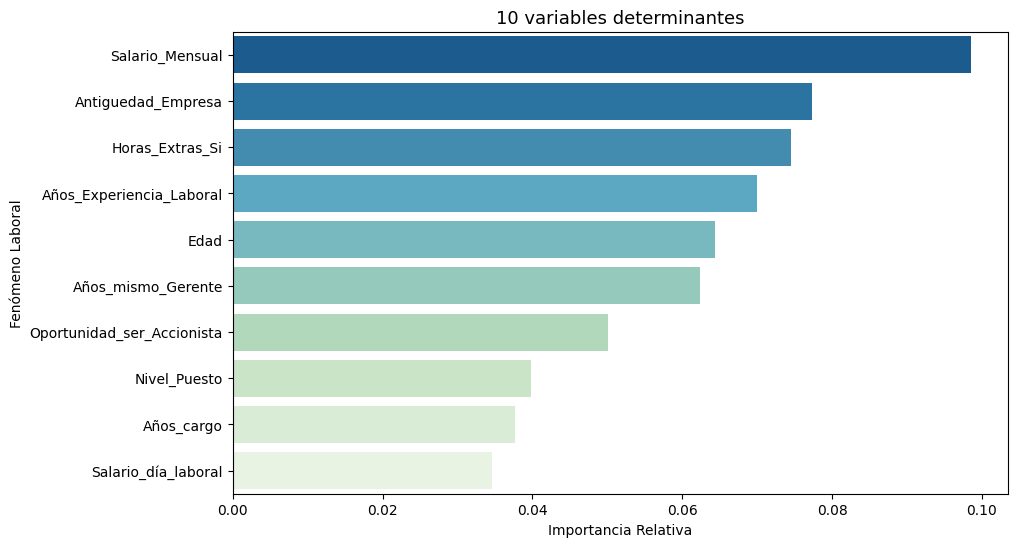

In [32]:
df_imp_rf = pd.DataFrame({
    'Variable': X_encoded.columns,
    'Importancia': modelo_rf.feature_importances_
}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_imp_rf.head(10),
    x='Importancia',
    y='Variable',
    palette='GnBu_r'
)
plt.title("10 variables determinantes", fontsize=13)
plt.xlabel("Importancia Relativa")
plt.ylabel("Fenómeno Laboral")
plt.show()

**Riesgo Latente**

In [33]:
df_eval_rf = X_test.copy()
df_eval_rf['Real_Renuncio'] = y_test
df_eval_rf['Probabilidad_Renuncia_%'] = (y_prob_rf * 100).round(1)

def nivel_riesgo_rf(p):
    if p >= 70:
        return 'Crítico'
    elif p >= 40:
        return 'Medio'
    else:
        return 'Bajo'

df_eval_rf['Nivel_Riesgo'] = df_eval_rf['Probabilidad_Renuncia_%'].apply(nivel_riesgo_rf)

riesgo_latente_rf = df_eval_rf[
    (df_eval_rf['Real_Renuncio'] == 0) &
    (df_eval_rf['Nivel_Riesgo'].isin(['Crítico', 'Medio']))
].sort_values(by='Probabilidad_Renuncia_%', ascending=False)

print("\nDistribución de Riesgo")
print(df_eval_rf['Nivel_Riesgo'].value_counts())

print(f"\nRiesgo Detectado: {len(riesgo_latente_rf)}")
display(riesgo_latente_rf[['Probabilidad_Renuncia_%', 'Nivel_Riesgo']].head(10))


Distribución de Riesgo
Nivel_Riesgo
Bajo       189
Medio       95
Crítico     10
Name: count, dtype: int64

Riesgo Detectado: 71


,Probabilidad_Renuncia_%,Nivel_Riesgo
301,84.5,Crítico
670,77.2,Crítico
1311,74.4,Crítico
109,74.4,Crítico
764,72.2,Crítico
1061,72.2,Crítico
1118,70.4,Crítico
17,68.8,Medio
476,67.6,Medio
1402,67.1,Medio


Los umbrales utilizados son parámetros operativos definidos para este caso de estudio y no corresponden a puntos de corte clínicos ni universalmente establecidos.

**SHAP como herramienta de interpretabilidad.**

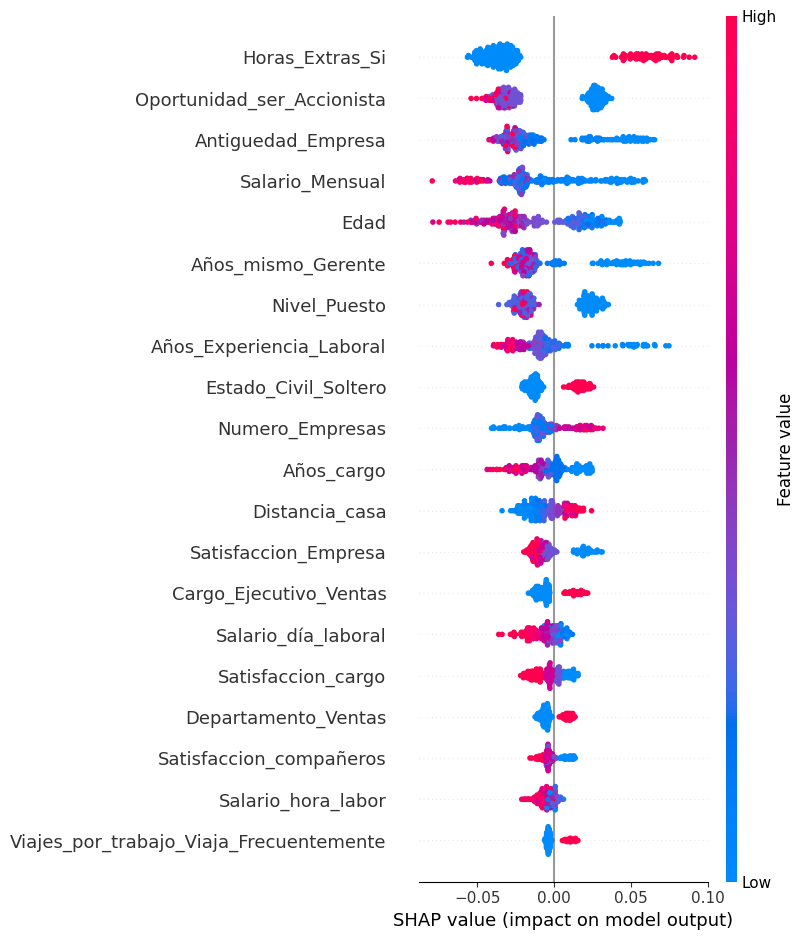

In [34]:
explainer = shap.TreeExplainer(modelo_rf)
shap_values = explainer.shap_values(X_test)
## Depende la versión
if isinstance(shap_values, list):
    shap_renuncia = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_renuncia = shap_values[:, :, 1]
else:
    shap_renuncia = shap_values

# Resumen
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_renuncia,
    X_test,
    feature_names=X_encoded.columns,
    show=True
)

**Se aclara que la intención del proyecto es simular una empresa real, por esto, se habla de población en riesgo, se deja en claro que es un caso simulado y que por eso se emplean esos conceptos.**

# 4. FASE: Ejecutar

## 4.1 Síntesis Comparativa de Modelos y Selección Final
Se evaluaron tres enfoques algorítmicos con diferentes niveles de complejidad y representatividad:

| Modelo | ROC-AUC | Recall (Fuga) | Precision (Fuga) | F1-Score | Justificación Operativa |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Regresión Logística** | 0.7977 | 0.62 | 0.34 | 0.44 | Alta cobertura general, aunque genera un volumen excesivo de falsas alarmas operativas. |
| **Árbol de Decisión Podado** | 0.6990 | 0.64 | 0.32 | 0.43 | Excelente valor didáctico para identificar umbrales rígidos, sin embargo menor desempeño global en las métricas evaluadas. |
| **Random Forest (Seleccionado)** | **0.7763** | **0.55** | **0.46** | **0.50** | **Modelo candidato para una eventual implementación.:** Se selecciona como candidato considerando el equilibrio entre Recall, Precision y F1, sujeto a validación posterior. |

**Veredicto:** Se adopta el **Random Forest** como motor predictivo principal para la gestión preventiva de la plantilla activa, respaldado por la auditoría de interpretabilidad con SHAP.


## 4.2 Diagnóstico:
El cruce entre el consenso del ensamble y los valores de SHAP identificó que los resultados sugieren una asociación entre determinadas características laborales y la rotación observada:

1. **Sobrecarga por Horas Extras:**
   * Es el factor individual de mayor peso predictivo, siendo un elemento tenido en cuenta en cada uno de los modelos predictivos, y gracias a la técnica SHAP se puede observar su implicación en la presunta decisión de los colaboradores.
   * La asignación recurrente de jornada suplementaria aparentemente duplica la probabilidad de salida sin importar la antigüedad del colaborador.
2. **Desfase Salarial en Cargos Operativos y de Entrada:**
   * La baja remuneración mensual muestra una concentración marcada en la zona de riesgo crítico.
   * El salario actúa como un ancla de retención eficaz solo cuando se alinea con la mediana del mercado para los niveles de responsabilidad asignados.
3. **Vulnerabilidad Temprana en Perfiles Júnior:**
   * Los colaboradores jóvenes y con menos de 2.5 años de experiencia presentan la mayor propensión a la fuga cuando perciben ausencia de incentivos de largo plazo.

---

## 4.3 Plan Estratégico de Intervención

### 1. Política Integral de Control de Jornada Laboral
* **Acción:** Establecer topes estrictos a las horas extras continuas por equipo, fijando alertas tempranas al superar umbrales semanales críticos.
* **Impacto esperado:** Mitigación directa del riesgo psicosocial por agotamiento y reducción el que aparentemente es el principal detonante de desvinculación voluntaria, además protege a la empresa de futuras demandas laborales o multas del Ministerio de Trabajo.

### 2. Nivelación de Bandas Salariales
* **Acción:** Revisar la equidad interna y competitividad externa en los roles operativos con menor compensación base.
* **Impacto esperado:** Frenar la fuga de talento calificado hacia ofertas salariales del mercado en los primeros 18 meses de permanencia, aumentar la competitividad es una estrategia que puede traer a largo plazo un mayor retorno en la empresa, evitando reprocesos y también aportando al ROI de contratación.



## 4.4 Protocolo Operativo y Monitoreo Continuo
* **Corte Mensual de Riesgo:** Ejecutar el modelo mensualmente sobre la nómina activa para actualizar el semáforo de riesgo 'Crítico, Medio, Bajo'.
* **Triaje Preventivo:** Concentrar las intervenciones personalizadas de Gestión Humana exclusivamente en el segmento clasificado con riesgo crítico.
* **Gobernanza del Algoritmo:** Reentrenar el modelo semestralmente para recalibrar los pesos conforme maduren las medidas de mitigación y cambien las condiciones del mercado laboral.